# Lab 3: Transfer Learning for Environmental Sound Classification

Template notebook for IT 480. It follows the lab stages in order. The metadata file `esc50.csv` is already wired up. The audio clips are not in this folder yet.

**Write these yourself, before you rely on the matching code cells:** Stage 0, each prediction, each checkpoint explanation, and the reflection. Those cells are blank on purpose.

## How to use this notebook

1. Keep the kernel's working directory as this folder (`Lab3`), or change `METADATA_CSV` and `AUDIO_DIR` in the setup cell.
2. When you add the ESC-50 clips, point `AUDIO_DIR` at the folder that contains the `.wav` files. In the official archive that folder is `ESC-50-master/audio/`. A clip path should look like `audio/1-100032-A-0.wav`, using the `filename` column from `esc50.csv`.
3. Finish Stage 0, then complete one stage at a time. Run the checkpoint and read the output before moving on.
4. This lab is meant to run in Google Colab with a GPU runtime (TensorFlow and Keras 3). Training on CPU will be very slow.
5. Do not turn on data augmentation. Keep YAMNet frozen. Use the same split, image size, and training settings for both image models.

## What you are comparing

| Approach | Input | Pretraining | Training |
| --- | --- | --- | --- |
| MobileNetV2 | Spectrogram image | ImageNet | Phase 1: frozen base. Phase 2: fine-tune the top of the base. |
| A second ImageNet model | Same spectrogram images | ImageNet | Same two phases and the same settings as MobileNetV2. Choose EfficientNetB0, DenseNet121, ResNet50, or ConvNeXtTiny. |
| YAMNet | Raw waveform | YouTube audio (AudioSet) | Frozen feature extractor, then a new classifier on one embedding per clip. |


## Stage 0: Design plan

Answer each question in two to four sentences before you implement the split or the models. Run the setup cells first so you can look at `esc50.csv` while you decide on the split.

### 1. Splitting

How will you form the training and validation sets? What could go wrong with a simple random split on this dataset? The validation set must contain 400 clips. Look at the metadata columns before you decide.

**Answer: There are 5 folds with 400 clips each which sums to the total amount of clips in the data. If we use 4 folds for training and 1 for validation, this resembles the classic 80, 20 split. Some audio clips are taken from the same original clip. Splitting these randomly would allow the model to "cheat" beacause it could hear background noise that is present in both clips (from the same original clip). It would determine two different noises are the same because the background noise.**

### 2. Audio as images

How will you turn each clip into an image an ImageNet model can accept? Consider size, number of channels, and value range.

**Answer: To turn each audio clip in the ESC-50 dataset into an image that a standard ImageNet model can accept, we need to transform the 1D audio waveform into a 2D Mel Spectrogram and format it to match the expected 3-channel RGB shape.**

### 3. Audio for YAMNet

What input does YAMNet expect, and how does that differ from the raw ESC-50 files?

**Answer: YAMNet expects an array of raw audio samples (Tensor or NumPy) which differ from the raw ESC-50 files in a directory.**

### 4. Fine-tuning plan

What will be frozen in phase 1? What will you unfreeze in phase 2, and with what learning rate relative to phase 1? Why?

**Answer: The base layers from YAMNet will be frozen as a feature extracter in phase 1. The top part of the base will be unfrozen in phase 2 with a smaller learning rate. A small part being unfrozen along with a smaller learning rate will prevent *catastrophic forgetting* and change the weights that are already proficient**

### 5. Fair comparison

What must stay the same between the two image models, and why?

**Answer: The two image models must use the same split, image size, and training settings, so that the comparison is fair.**


## Setup

Run the cells in this section first. They load `esc50.csv` and check whether the wav files are present. Later stages stop with a clear error until you fill in the decisions from Stage 0.


In [ ]:
# Colab dataset setup: uploading 2000 wav files one-by-one often drops files.
# Prefer downloading the official zip once, then point METADATA_CSV / AUDIO_DIR at it.

from pathlib import Path
import urllib.request
import zipfile

ESC50_ZIP_URL = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"
ESC50_ZIP = Path("/content/ESC-50-master.zip")
ESC50_ROOT = Path("/content/ESC-50-master")

if Path("/content").exists():
    audio_dir = ESC50_ROOT / "audio"
    n_wavs = len(list(audio_dir.glob("*.wav"))) if audio_dir.is_dir() else 0
    if n_wavs < 2000:
        print(f"Found {n_wavs} wavs under {audio_dir}; downloading full ESC-50...")
        urllib.request.urlretrieve(ESC50_ZIP_URL, ESC50_ZIP)
        with zipfile.ZipFile(ESC50_ZIP, "r") as zf:
            zf.extractall("/content")
        print("Unzipped to", ESC50_ROOT)
    else:
        print(f"ESC-50 already present with {n_wavs} wavs at {audio_dir}")

    # Use these paths in the next cell (or keep your local paths outside Colab).
    print("Suggested Colab paths:")
    print("  METADATA_CSV = Path('/content/ESC-50-master/meta/esc50.csv')")
    print("  AUDIO_DIR    = Path('/content/ESC-50-master/audio')")
else:
    print("Not running under /content; skip Colab download.")

Found 0 wavs under /content/ESC-50-master/audio; downloading full ESC-50...
Unzipped to /content/ESC-50-master
Suggested Colab paths:
  METADATA_CSV = Path('/content/ESC-50-master/meta/esc50.csv')
  AUDIO_DIR    = Path('/content/ESC-50-master/audio')


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from IPython.display import Audio, display
from scipy.signal import resample

# Prefer the full unzipped ESC-50 tree (2000 wavs). Manual /content/audio uploads
# are often incomplete (your Colab run had 1685/2000).
_candidates = [
    (Path("/content/ESC-50-master/meta/esc50.csv"), Path("/content/ESC-50-master/audio")),
    (Path("ESC-50-master/meta/esc50.csv"), Path("ESC-50-master/audio")),
    (Path("/content/esc50.csv"), Path("/content/audio")),
    (Path("esc50.csv"), Path("audio")),
]
METADATA_CSV, AUDIO_DIR = next(
    ((meta, audio) for meta, audio in _candidates if meta.exists() and audio.is_dir()),
    _candidates[0],
)
print("METADATA_CSV:", METADATA_CSV)
print("AUDIO_DIR:", AUDIO_DIR)

# One of: "EfficientNetB0", "DenseNet121", "ResNet50", "ConvNeXtTiny"
SECOND_MODEL_NAME = "EfficientNetB0"

# Shared by both image models. Phase 2 LR is much smaller than phase 1.
TRAINING = {
    "image_size": (224, 224),
    "batch_size": 32,
    "phase1_learning_rate": 1e-3,
    "phase1_epochs": 20,
    "phase2_learning_rate": 1e-5,
    "phase2_epochs": 10,
    "dropout": 0.3,
    "early_stopping_patience": 5,
    "validation_clips": 400,
    "num_classes": 50,
    "seed": 480,
}

# Unfreeze this many layers from the top of each ImageNet base in phase 2.
FINE_TUNE_TOP_LAYERS = 40

YAMNET_SAMPLE_RATE = 16000
YAMNET_HANDLE = "https://tfhub.dev/google/yamnet/1"
MEL_BINS = 128
STFT_FRAME_LENGTH = 2048
STFT_FRAME_STEP = 512

# Filled in as you train. Stage 7 reads these.
histories = {}
results = []

tf.random.set_seed(TRAINING["seed"])
np.random.seed(TRAINING["seed"])

print("working directory:", Path.cwd())
print("TensorFlow", tf.__version__)
print("Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "none (in Colab: Runtime → Change runtime type → GPU)")


METADATA_CSV: /content/ESC-50-master/meta/esc50.csv
AUDIO_DIR: /content/ESC-50-master/audio
working directory: /content
TensorFlow 2.21.0
Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
if not METADATA_CSV.exists():
    raise FileNotFoundError(
        f"Could not find {METADATA_CSV.resolve()}. "
        "Run this notebook from the Lab3 folder, or change METADATA_CSV."
    )

meta = pd.read_csv(METADATA_CSV)

assert len(meta) == 2000, len(meta)
assert meta["category"].nunique() == 50
assert meta["target"].nunique() == 50
assert meta.groupby("category").size().eq(40).all()
assert set(meta["fold"].tolist()) == {1, 2, 3, 4, 5}
assert meta.groupby("fold").size().eq(400).all()
assert meta.groupby("target")["category"].nunique().max() == 1

CLASS_NAMES = (
    meta.sort_values("target")[["target", "category"]]
    .drop_duplicates()
    .sort_values("target")["category"]
    .tolist()
)
assert CLASS_NAMES[0] == meta.loc[meta["target"] == 0, "category"].iloc[0]
assert len(CLASS_NAMES) == 50

meta.head(10)


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
5,1-101296-B-19.wav,1,19,thunderstorm,False,101296,B
6,1-101336-A-30.wav,1,30,door_wood_knock,False,101336,A
7,1-101404-A-34.wav,1,34,can_opening,False,101404,A
8,1-103298-A-9.wav,1,9,crow,False,103298,A
9,1-103995-A-30.wav,1,30,door_wood_knock,False,103995,A


In [ ]:
# Use this cell while you write the Stage 0 splitting answer.
# Columns that matter: filename, fold, target, category, src_file, take.
print("clips", len(meta))
print(meta.nunique())
print()
print("clips per fold")
print(meta.groupby("fold").size())
print()
print("clips per class (should be 40)")
print(meta.groupby("category").size().describe())

# How src_file relates to fold and category. Use the src_file column only.
clips_per_src = meta.groupby("src_file").size()
print()
print("clips per src_file")
print(clips_per_src.value_counts().sort_index())

folds_per_src = meta.groupby("src_file")["fold"].nunique()
categories_per_src = meta.groupby("src_file")["category"].nunique()
print()
print("src_file values that appear in more than one fold:", int((folds_per_src > 1).sum()))
print("src_file values that appear in more than one category:", int((categories_per_src > 1).sum()))

cross_fold_src = folds_per_src[folds_per_src > 1].index
if len(cross_fold_src):
    print()
    print("src_file values that cross folds (and their categories):")
    print(
        meta.loc[meta["src_file"].isin(cross_fold_src), ["src_file", "fold", "category"]]
        .drop_duplicates()
        .sort_values(["src_file", "fold"])
        .to_string(index=False)
    )

same_class_multi = meta.groupby("src_file").filter(
    lambda g: g["category"].nunique() == 1 and len(g) > 1
)
print()
print(
    "src_file values with multiple same-class takes:",
    same_class_multi["src_file"].nunique(),
)
print(
    "Example: one src_file with repeated takes of the same class:\n",
    same_class_multi.groupby("src_file")
    .size()
    .sort_values(ascending=False)
    .head(3)
    .to_string(),
)

clips 2000
filename    2000
fold           5
target        50
category      50
esc10          2
src_file    1524
take           8
dtype: int64

clips per fold
fold
1    400
2    400
3    400
4    400
5    400
dtype: int64

clips per class (should be 40)
count    50.0
mean     40.0
std       0.0
min      40.0
25%      40.0
50%      40.0
75%      40.0
max      40.0
dtype: float64

clips per src_file
1    1205
2     230
3      51
4      23
5       8
6       2
7       2
8       3
Name: count, dtype: int64

src_file values that appear in more than one fold: 4
src_file values that appear in more than one category: 4

src_file values that cross folds (and their categories):
 src_file  fold    category
   131943     2  clock_tick
   131943     3 clock_alarm
   134049     2         hen
   134049     3     rooster
   209698     4 clock_alarm
   209698     5  clock_tick
   234879     4         hen
   234879     5     rooster

src_file values with multiple same-class takes: 315
Example: one src_fi

In [ ]:
def wav_path(filename: str) -> Path:
    return AUDIO_DIR / filename


def audio_file_count() -> int:
    if not AUDIO_DIR.is_dir():
        return 0
    return len(list(AUDIO_DIR.glob("*.wav")))


def require_audio() -> int:
    n = audio_file_count()
    if n == 0:
        raise FileNotFoundError(
            f"No wav files in {AUDIO_DIR.resolve()}.\n"
            "Unzip ESC-50 and set AUDIO_DIR to the folder that contains the clips "
            "(official archive: ESC-50-master/audio/). "
            "Each meta['filename'] value should exist in that folder."
        )
    return n


def verify_audio_matches_metadata(frame: pd.DataFrame, n_check: int | None = None) -> None:
    """Fail fast if AUDIO_DIR is missing any filenames from the metadata."""
    require_audio()
    names = frame["filename"].tolist() if n_check is None else frame["filename"].head(n_check).tolist()
    missing = [name for name in names if not wav_path(name).exists()]
    n_wavs = audio_file_count()
    if missing or n_wavs < 2000:
        sample = sorted(AUDIO_DIR.glob("*.wav"))[:5]
        raise FileNotFoundError(
            f"AUDIO_DIR={AUDIO_DIR.resolve()} has {n_wavs} wav files (ESC-50 needs 2000).\n"
            f"Missing examples: {missing[:10]}\n"
            f"Files actually present (sample): {[p.name for p in sample]}\n"
            "Do not upload 2000 wavs by hand in Colab — run the Colab download cell, then use:\n"
            "  METADATA_CSV = Path('/content/ESC-50-master/meta/esc50.csv')\n"
            "  AUDIO_DIR = Path('/content/ESC-50-master/audio')"
        )


AUDIO_READY = audio_file_count() > 0
print(f"AUDIO_DIR = {AUDIO_DIR.resolve()}")
print(f"wav files found: {audio_file_count()} (ESC-50 expects 2000)")
if not AUDIO_READY:
    print("Metadata is ready. Add the wav files before the listening, plotting, and training cells.")
elif audio_file_count() < 2000:
    print(
        f"WARNING: only {audio_file_count()} wavs found. "
        "Re-run the Colab download/unzip cell; manual uploads are often incomplete."
    )
else:
    print("Example wav in AUDIO_DIR:", next(AUDIO_DIR.glob("*.wav")).name)


AUDIO_DIR = /content/ESC-50-master/audio
wav files found: 2000 (ESC-50 expects 2000)
Example wav in AUDIO_DIR: 3-152020-C-36.wav


In [ ]:
def assert_training_config() -> None:
    missing = [key for key, value in TRAINING.items() if value is None]
    if missing:
        raise ValueError(
            "Fill these TRAINING entries from your Stage 0 decisions before training: "
            + ", ".join(missing)
        )
    height, width = TRAINING["image_size"]
    if height <= 0 or width <= 0:
        raise ValueError("TRAINING['image_size'] must be (height, width).")


def load_wav(path: Path):
    """Load one ESC-50 clip as mono float32 samples in [-1, 1], plus the sample rate."""
    audio, sample_rate = tf.audio.decode_wav(tf.io.read_file(str(path)))
    audio = tf.reduce_mean(audio, axis=-1)
    return audio, int(sample_rate)


## Stage 1: Data and splitting

Load the metadata and audio, listen to several clips, and plot a few waveforms and mel spectrograms. Then build the training and validation split.

The validation set must contain 400 clips. You choose how to form it. Checkpoint 1 is where you show that the split does not leak, and that every class appears in both sets.


In [ ]:
def show_clip(filename: str) -> None:
    """Play one clip and plot its waveform. Extend this to mel spectrograms below."""
    require_audio()
    path = wav_path(filename)
    if not path.exists():
        raise FileNotFoundError(path)
    audio, sample_rate = load_wav(path)
    row = meta.loc[meta["filename"] == filename].iloc[0]
    print(f"{filename}  class={row['category']}  fold={row['fold']}  src_file={row['src_file']}")
    print(f"samples={audio.shape[0]}  sample_rate={sample_rate}  duration={audio.shape[0] / sample_rate:.2f}s")
    display(Audio(audio.numpy(), rate=sample_rate))
    plt.figure(figsize=(8, 2.5))
    time_axis = np.arange(audio.shape[0]) / sample_rate
    plt.plot(time_axis, audio.numpy(), linewidth=0.6)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(f"{row['category']}: {filename}")
    plt.tight_layout()
    plt.show()


# TODO: pick several filenames from different classes, call show_clip, and plot a mel spectrogram for each.
# Skip this until AUDIO_READY is True.
if not AUDIO_READY:
    print("Skipping listening plots until wav files are in AUDIO_DIR.")


In [ ]:
VALIDATION_FOLD = 5


def make_split(metadata: pd.DataFrame):
    """Hold out one official ESC-50 fold as the 400-clip validation set.

    Fold 5 is validation. Folds 1-4 are training. Each fold has 8 clips per
    class, and clips that share a src_file are almost always in the same fold,
    so repeated takes of one recording do not land on both sides.
    """
    val_df = metadata.loc[metadata["fold"] == VALIDATION_FOLD].copy()
    train_df = metadata.loc[metadata["fold"] != VALIDATION_FOLD].copy()
    if len(val_df) != TRAINING["validation_clips"]:
        raise ValueError(
            f"Fold {VALIDATION_FOLD} has {len(val_df)} clips, "
            f"expected {TRAINING['validation_clips']}."
        )
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True)


train_df, val_df = make_split(meta)
print("train", len(train_df), "val", len(val_df))
print("val clips per class:")
print(val_df.groupby("category").size().describe())


train 1600 val 400
val clips per class:
count    50.0
mean      8.0
std       0.0
min       8.0
25%       8.0
50%       8.0
75%       8.0
max       8.0
dtype: float64


### Checkpoint 1: Checking for leakage

Show all of the following, then explain it in the next cell:

- Whether any `src_file` appears in both training and validation. If any do, list them, check whether they have the same class on both sides, and say whether that could inflate validation accuracy.
- Every class appears in both sets, and how many clips per class are in each set.


In [ ]:
overlap = sorted(set(train_df["src_file"]).intersection(set(val_df["src_file"])))
print("source recordings in both train and val:", len(overlap))

# TODO: if overlap is not empty, list those src_file values and whether each
# source has the same category in train and in val.
for src in overlap:
    train_cats = sorted(train_df.loc[train_df["src_file"] == src, "category"].unique())
    val_cats = sorted(val_df.loc[val_df["src_file"] == src, "category"].unique())
    same_class = set(train_cats) == set(val_cats)
    print(
        f"src_file={src}: train={train_cats}, val={val_cats}, "
        f"same class on both sides={same_class}"
    )

train_counts = train_df.groupby("category").size().sort_index()
val_counts = val_df.groupby("category").size().sort_index()
counts = pd.DataFrame({"train": train_counts, "val": val_counts}).fillna(0).astype(int)
print(counts.to_string())

missing_train = sorted(set(CLASS_NAMES) - set(train_counts.index))
missing_val = sorted(set(CLASS_NAMES) - set(val_counts.index))
print("classes missing from train:", missing_train)
print("classes missing from val:", missing_val)
assert len(val_df) == TRAINING["validation_clips"]
assert not missing_train and not missing_val


source recordings in both train and val: 2
src_file=209698: train=['clock_alarm'], val=['clock_tick'], same class on both sides=False
src_file=234879: train=['hen'], val=['rooster'], same class on both sides=False
                  train  val
category                    
airplane             32    8
breathing            32    8
brushing_teeth       32    8
can_opening          32    8
car_horn             32    8
cat                  32    8
chainsaw             32    8
chirping_birds       32    8
church_bells         32    8
clapping             32    8
clock_alarm          32    8
clock_tick           32    8
coughing             32    8
cow                  32    8
crackling_fire       32    8
crickets             32    8
crow                 32    8
crying_baby          32    8
dog                  32    8
door_wood_creaks     32    8
door_wood_knock      32    8
drinking_sipping     32    8
engine               32    8
fireworks            32    8
footsteps            32    8
fro

**Checkpoint 1 explanation:**

Two `src_file` values still appear on both sides: `209698` is `clock_alarm` in training and `clock_tick` in validation, and `234879` is `hen` in training and `rooster` in validation. Neither is the same class on both sides, so the model is not seeing a held-out take of a sound it already trained on. That is the leakage that would inflate accuracy, and it is not happening here.

A weak shared recording identity across related sounds (alarm vs tick, hen vs rooster) is possible in theory, but it is tiny next to the risk of a random clip split, which would put many same-class repeated takes on both sides. The official fold split is the better choice for this lab.


## Stage 2: Preparing inputs

Convert clips into spectrogram images for the image models, and into the waveform YAMNet expects.

Image size has to be shared by both image models. The numeric preprocessing does not: each architecture needs the `preprocess_input` that matches its ImageNet weights. YAMNet does not take that image.


In [ ]:
def waveform_to_log_mel(audio: tf.Tensor, sample_rate: int) -> tf.Tensor:
    """Convert a mono waveform to a log-mel spectrogram with shape [time, mel].

    STFT / mel ops are forced onto CPU. On Colab GPUs, tf.signal.stft and
    linear_to_mel_weight_matrix often crash inside tf.data with reshape errors.
    """
    sample_rate = int(sample_rate)
    num_spectrogram_bins = STFT_FRAME_LENGTH // 2 + 1

    with tf.device("/CPU:0"):
        audio = tf.cast(audio, tf.float32)
        stft = tf.signal.stft(
            audio,
            frame_length=STFT_FRAME_LENGTH,
            frame_step=STFT_FRAME_STEP,
            fft_length=STFT_FRAME_LENGTH,
        )
        spectrogram = tf.abs(stft)
        mel_weight_matrix = tf.signal.linear_to_mel_weight_matrix(
            num_mel_bins=MEL_BINS,
            num_spectrogram_bins=num_spectrogram_bins,
            sample_rate=float(sample_rate),
            lower_edge_hertz=20.0,
            upper_edge_hertz=float(sample_rate) / 2.0,
        )
        mel_spectrogram = tf.matmul(tf.square(spectrogram), mel_weight_matrix)
        return tf.math.log(mel_spectrogram + 1e-6)


def clip_to_spectrogram_image(filename: str, preprocess_input):
    """Return the image tensor that an ImageNet model will receive for one clip.

    Builds a log-mel spectrogram, resizes it to TRAINING["image_size"], repeats
    it to 3 channels in [0, 255], then applies the model-specific preprocess_input.
    """
    if TRAINING["image_size"] is None:
        raise ValueError("Set TRAINING['image_size'] before building spectrogram images.")

    with tf.device("/CPU:0"):
        audio, sample_rate = load_wav(wav_path(filename))
        log_mel = waveform_to_log_mel(audio, sample_rate)

        # Shape for image ops: [1, time, mel, 1]
        image = log_mel[tf.newaxis, ..., tf.newaxis]
        image = tf.image.resize(image, TRAINING["image_size"])
        image = tf.squeeze(image, axis=0)

        # Scale log-mel values to [0, 255] the way ImageNet preprocess_input expects.
        image_min = tf.reduce_min(image)
        image_max = tf.reduce_max(image)
        image = (image - image_min) / (image_max - image_min + 1e-8)
        image = image * 255.0
        image = tf.repeat(image, repeats=3, axis=-1)

        image = preprocess_input(image)
        return tf.cast(image, tf.float32)


def make_image_dataset(frame: pd.DataFrame, preprocess_input, shuffle: bool):
    """Build a tf.data dataset of (image, integer target) pairs from a split frame.

    Spectrogram images are precomputed on CPU once, then fed from memory. That
    avoids tf.py_function + GPU signal ops, which crash on Colab.
    """
    if TRAINING["batch_size"] is None:
        raise ValueError("Set TRAINING['batch_size'] before building image datasets.")

    verify_audio_matches_metadata(frame)

    filenames = frame["filename"].tolist()
    labels = frame["target"].to_numpy(dtype=np.int32)
    height, width = TRAINING["image_size"]

    print(f"Precomputing {len(filenames)} spectrogram images on CPU...")
    images = np.empty((len(filenames), height, width, 3), dtype=np.float32)
    for i, filename in enumerate(filenames):
        images[i] = clip_to_spectrogram_image(filename, preprocess_input).numpy()
        if (i + 1) % 100 == 0 or (i + 1) == len(filenames):
            print(f"  {i + 1}/{len(filenames)}")

    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(filenames),
            seed=TRAINING["seed"],
            reshuffle_each_iteration=True,
        )
    ds = ds.batch(TRAINING["batch_size"]).prefetch(tf.data.AUTOTUNE)
    return ds


In [ ]:
def clip_to_yamnet_waveform(filename: str):
    """Return a 1-D float32 waveform for YAMNet.

    YAMNet wants mono audio at 16 kHz with samples in [-1.0, 1.0].
    ESC-50 clips are 44,100 Hz mono float WAV, so this only resamples.
    """
    audio, sample_rate = load_wav(wav_path(filename))
    audio_np = audio.numpy().astype(np.float32)

    if sample_rate != YAMNET_SAMPLE_RATE:
        target_length = int(round(len(audio_np) * YAMNET_SAMPLE_RATE / sample_rate))
        audio_np = resample(audio_np, target_length).astype(np.float32)

    # Keep the amplitude range YAMNet expects after resampling.
    peak = np.max(np.abs(audio_np))
    if peak > 1.0:
        audio_np = audio_np / peak

    return tf.convert_to_tensor(audio_np, dtype=tf.float32)


def clip_to_yamnet_embedding(filename: str, yamnet_model):
    """Return one embedding vector for one clip.

    YAMNet returns a sequence of frame embeddings. Average them to get one
    clip-level embedding for the classifier in Stage 6.
    """
    waveform = clip_to_yamnet_waveform(filename)
    scores, embeddings, spectrogram = yamnet_model(waveform)
    return tf.reduce_mean(embeddings, axis=0)


### Checkpoint 2: Inputs are what the models expect

- For a spectrogram image: print shape, dtype, minimum, and maximum, and explain how those match the image model's preprocessing.
- For YAMNet input: show the sampling rate, the number of samples in a five-second clip, the dtype, and the value range.
- Display one spectrogram image exactly as the model receives it.


example clip: 1-100032-A-0.wav

Spectrogram image for MobileNetV2
  shape: (224, 224, 3)
  dtype: <dtype: 'float32'>
  min: -1.0
  max: 1.0


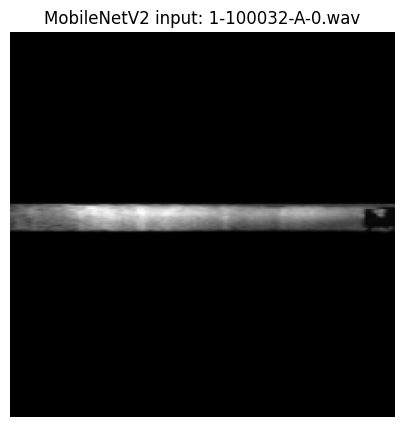


YAMNet waveform
  sample_rate_hz: 16000
  num_samples: 80000
  expected_samples_for_5s: 80000
  dtype: <dtype: 'float32'>
  min: -0.9502525329589844
  max: 0.9871464371681213


In [ ]:
require_audio()
if TRAINING["image_size"] is None:
    raise ValueError("Set TRAINING['image_size'] before Checkpoint 2.")

example_filename = train_df["filename"].iloc[0]
print("example clip:", example_filename)

mobilenet_preprocess = keras.applications.mobilenet_v2.preprocess_input
spec_image = clip_to_spectrogram_image(example_filename, mobilenet_preprocess)
print("\nSpectrogram image for MobileNetV2")
print("  shape:", tuple(spec_image.shape))
print("  dtype:", spec_image.dtype)
print("  min:", float(tf.reduce_min(spec_image)))
print("  max:", float(tf.reduce_max(spec_image)))

# Display the image exactly as the model receives it (MobileNetV2 preprocess -> [-1, 1]).
plt.figure(figsize=(5, 5))
plt.imshow(((spec_image.numpy() + 1.0) / 2.0).clip(0.0, 1.0))
plt.title(f"MobileNetV2 input: {example_filename}")
plt.axis("off")
plt.show()

yamnet_wave = clip_to_yamnet_waveform(example_filename)
print("\nYAMNet waveform")
print("  sample_rate_hz:", YAMNET_SAMPLE_RATE)
print("  num_samples:", int(yamnet_wave.shape[0]))
print("  expected_samples_for_5s:", YAMNET_SAMPLE_RATE * 5)
print("  dtype:", yamnet_wave.dtype)
print("  min:", float(tf.reduce_min(yamnet_wave)))
print("  max:", float(tf.reduce_max(yamnet_wave)))


**Checkpoint 2 explanation:**

The shape data type and min/max values match what the image model's preprocessing expects. The shape is 224, 224, 3 which matches our image_size value. The data type is 32, which is what keras expects and the min/max values match what MobileNetV2 preprocess_input scales to.  

As seen above (for YAMNet), our sample rate is 16000Hz. YAMNet wants 16 kHz and ESC-50 is 44.1 kHz, so we resampled. There are 80000 samples, a data type of float32, and the value range is roughly -0.95 to 0.99.


## Stage 3: MobileNetV2, phase 1

Train a new classification head with the ImageNet base frozen. Store the Keras history in `histories["mobilenet_phase1"]` and append the validation accuracy to `results`.


### Prediction 1

Write this before you train. What validation accuracy do you expect with a frozen MobileNetV2 base? Why?

**Prediction:**

Given that the data is extremely small and ImageNet was trained on photos when our input is mel spectograms, we are predicting around 55% validation accuracy.



In [ ]:
PREPROCESS = {
    "MobileNetV2": keras.applications.mobilenet_v2.preprocess_input,
    "EfficientNetB0": keras.applications.efficientnet.preprocess_input,
    "DenseNet121": keras.applications.densenet.preprocess_input,
    "ResNet50": keras.applications.resnet50.preprocess_input,
    "ConvNeXtTiny": keras.applications.convnext.preprocess_input,
}


def build_image_model(base_model, dropout):
    """Classifier head on top of base_model.

    Call the frozen/fine-tuned base with training=False so BatchNormalization
    layers keep their pretrained moving statistics (Checkpoint 4).
    """
    inputs = keras.Input(shape=(*TRAINING["image_size"], 3))
    x = base_model(inputs, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(TRAINING["num_classes"], activation="softmax")(x)
    return keras.Model(inputs, outputs)


def compile_and_fit(model, train_data, val_data, learning_rate, epochs, history_name):
    """Compile, fit, store history, and append best validation accuracy to results.

    train_data / val_data may be a tf.data.Dataset or an (x, y) numpy tuple.
    """
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=TRAINING["early_stopping_patience"],
            restore_best_weights=True,
        )
    ]

    fit_kwargs = {
        "validation_data": val_data,
        "epochs": epochs,
        "callbacks": callbacks,
    }
    if isinstance(train_data, tuple):
        x_train, y_train = train_data
        history = model.fit(
            x_train,
            y_train,
            batch_size=TRAINING["batch_size"],
            **fit_kwargs,
        )
    else:
        history = model.fit(train_data, **fit_kwargs)

    histories[history_name] = history
    best_val = float(max(history.history["val_accuracy"]))
    results.append({"approach": history_name, "validation_accuracy": best_val})
    print(f"{history_name}: best val_accuracy={best_val:.4f}")
    return history


def set_base_trainable(base_model, trainable: bool, top_layers: int | None = None) -> None:
    """Freeze the whole base, or unfreeze only the last top_layers."""
    if not trainable:
        base_model.trainable = False
        return

    base_model.trainable = True
    if top_layers is None:
        return
    freeze_until = max(0, len(base_model.layers) - top_layers)
    for i, layer in enumerate(base_model.layers):
        layer.trainable = i >= freeze_until


assert_training_config()

mobilenet_preprocess = PREPROCESS["MobileNetV2"]
train_img_ds = make_image_dataset(train_df, mobilenet_preprocess, shuffle=True)
val_img_ds = make_image_dataset(val_df, mobilenet_preprocess, shuffle=False)

mobilenet_base = keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(*TRAINING["image_size"], 3),
)
set_base_trainable(mobilenet_base, trainable=False)
mobilenet_model = build_image_model(mobilenet_base, TRAINING["dropout"])

compile_and_fit(
    mobilenet_model,
    train_img_ds,
    val_img_ds,
    learning_rate=TRAINING["phase1_learning_rate"],
    epochs=TRAINING["phase1_epochs"],
    history_name="MobileNetV2 (frozen)",
)

Precomputing 1600 spectrogram images on CPU...
  100/1600
  200/1600
  300/1600
  400/1600
  500/1600
  600/1600
  700/1600
  800/1600
  900/1600
  1000/1600
  1100/1600
  1200/1600
  1300/1600
  1400/1600
  1500/1600
  1600/1600
Precomputing 400 spectrogram images on CPU...
  100/400
  200/400
  300/400
  400/400
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 23s 205ms/step - accuracy: 0.1325 - loss: 3.4645 - val_accuracy: 0.3700 - val_loss: 2.5303
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.4087 - loss: 2.1083 - val_accuracy: 0.4675 - val_loss: 2.0272
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.5744 - loss: 1.5699 - val_accuracy: 0.5525 - val_loss: 1.8362
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.6656 - loss: 1.2508 - val_accuracy: 0.5550 - val_loss: 1.6794
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.7156 - loss: 1.0656 - val_accuracy: 0.5675 - val_loss: 1.600

### Checkpoint 3: Only the head is training

Print the number of trainable and non-trainable parameters, and explain why those numbers make sense.


In [ ]:
trainable_params = int(sum(np.prod(w.shape) for w in mobilenet_model.trainable_weights))
nontrainable_params = int(sum(np.prod(w.shape) for w in mobilenet_model.non_trainable_weights))
print("trainable:", trainable_params)
print("non-trainable:", nontrainable_params)
mobilenet_model.summary()


trainable: 64050
non-trainable: 2257984


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        64,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,450,136 (9.35 MB)

 Trainable params: 64,050 (250.20 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 128,102 (500.40 KB)

**Checkpoint 3 explanation:**

Only about 64,050 parameters are trainable, and about 2.26 million are frozen. That matches phase 1: the MobileNetV2 base stays fixed, and I’m only training the new classifier head on top. The head is a dense layer from 1280 features to 50 classes, which is 1280×50+50 = 64,050 weights, so the numbers make sense.



## Stage 4: MobileNetV2, phase 2

Unfreeze the top part of the base and continue training with a smaller learning rate than phase 1. Before `fit`, save copies of the weights so Checkpoint 4 can see what changed.

Store the history in `histories["mobilenet_phase2"]`.


### Prediction 2

Write this before phase 2. Will fine-tuning improve validation accuracy? By roughly how much? What do you expect to happen in the first epoch after unfreezing?

**Prediction:**

We expect fine-tuning to help a little, maybe by about 3–5 points over the frozen phase. In the first epoch after unfreezing, training accuracy will probably drop for a bit while the top layers adjust, and validation might dip or stay flat before it recovers with the smaller learning rate.


In [24]:
# Checkpoint 4 fix: unfreeze top conv layers, but keep ALL BatchNormalization frozen
# so moving_mean / moving_variance stay at ImageNet values.
set_base_trainable(
    mobilenet_base,
    trainable=True,
    top_layers=FINE_TUNE_TOP_LAYERS,
)

# Belt-and-suspenders: freeze every BN layer explicitly (Checkpoint 4).
for layer in mobilenet_base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

bn_frozen = sum(
    1
    for layer in mobilenet_base.layers
    if isinstance(layer, keras.layers.BatchNormalization) and not layer.trainable
)
print(f"BatchNormalization layers frozen: {bn_frozen}")

# Probe a BN layer that sits in the fine-tuned region of the base.
freeze_until = max(0, len(mobilenet_base.layers) - FINE_TUNE_TOP_LAYERS)
bn_probe_layer = None
for i, layer in enumerate(mobilenet_base.layers):
    if i >= freeze_until and isinstance(layer, keras.layers.BatchNormalization):
        bn_probe_layer = layer
if bn_probe_layer is None:
    raise RuntimeError("No BatchNormalization layer found in the fine-tuned region.")

print(f"BN probe layer: {bn_probe_layer.name}")
print(f"BN probe trainable (should be False): {bn_probe_layer.trainable}")
bn_moving_mean_before = bn_probe_layer.moving_mean.numpy().copy()
print("moving_mean before phase 2 (first 5):", bn_moving_mean_before[:5])

phase2_weights_before = [w.numpy().copy() for w in mobilenet_model.weights]

# Recompile after changing trainable flags.
compile_and_fit(
    mobilenet_model,
    train_img_ds,
    val_img_ds,
    learning_rate=TRAINING["phase2_learning_rate"],
    epochs=TRAINING["phase2_epochs"],
    history_name="MobileNetV2 (fine-tuned)",
)

bn_moving_mean_after = bn_probe_layer.moving_mean.numpy().copy()
print("moving_mean after phase 2 (first 5):", bn_moving_mean_after[:5])
print(
    "moving_mean changed:",
    not np.array_equal(bn_moving_mean_before, bn_moving_mean_after),
)

mobilenet_phase2_trainable = int(
    sum(np.prod(w.shape) for w in mobilenet_model.trainable_weights)
)
print(f"MobileNetV2 phase-2 trainable params: {mobilenet_phase2_trainable}")


BatchNormalization layers frozen: 52
BN probe layer: Conv_1_bn
BN probe trainable (should be False): False
moving_mean before phase 2 (first 5): [ 0.00015978 -0.00104797 -0.0002135  -0.00028357 -0.00045532]
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 271ms/step - accuracy: 0.9231 - loss: 0.2830 - val_accuracy: 0.6150 - val_loss: 1.5463
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.9456 - loss: 0.1978 - val_accuracy: 0.6275 - val_loss: 1.5368
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9519 - loss: 0.1734 - val_accuracy: 0.6250 - val_loss: 1.5494
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9656 - loss: 0.1435 - val_accuracy: 0.6200 - val_loss: 1.5528
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9619 - loss: 0.1367 - val_accuracy: 0.6075 - val_loss: 1.5627
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9675 - loss: 0.1314 - val_accuracy: 0.6300 - val_loss: 1.5221
Epoch 7/10
50/50 ━━━━━━━━━━━━

### Checkpoint 4: Fine-tuning does what you intend

- Show which layers' weights changed during phase 2 and which did not, by comparing the saved copies from before and after training.
- Pick one BatchNormalization layer in the unfrozen part of the base. Record its `moving_mean` before and after phase 2. If it changed, explain why that is a problem, find out why it happened, and fix it. Then show this check again.


In [25]:
changed = []
unchanged = []
for before, weight in zip(phase2_weights_before, mobilenet_model.weights):
    name = weight.path
    if np.array_equal(before, weight.numpy()):
        unchanged.append(name)
    else:
        changed.append(name)

print(f"weights changed: {len(changed)}")
print(f"weights unchanged: {len(unchanged)}")
print("changed weight names (first 30):")
for name in changed[:30]:
    print(" ", name)

print()
print(f"BN probe layer: {bn_probe_layer.name}")
print("moving_mean before (first 5):", bn_moving_mean_before[:5])
print("moving_mean after  (first 5):", bn_moving_mean_after[:5])
print(
    "moving_mean changed:",
    not np.array_equal(bn_moving_mean_before, bn_moving_mean_after),
)
# build_image_model calls the base with training=False, so BN moving stats
# should stay fixed even though the layer's gamma/beta may be trainable.

weights changed: 15
weights unchanged: 247
changed weight names (first 30):
  block_13_expand/kernel
  block_13_depthwise/kernel
  block_13_project/kernel
  block_14_expand/kernel
  block_14_depthwise/kernel
  block_14_project/kernel
  block_15_expand/kernel
  block_15_depthwise/kernel
  block_15_project/kernel
  block_16_expand/kernel
  block_16_depthwise/kernel
  block_16_project/kernel
  Conv_1/kernel
  dense/kernel
  dense/bias

BN probe layer: Conv_1_bn
moving_mean before (first 5): [ 0.00015978 -0.00104797 -0.0002135  -0.00028357 -0.00045532]
moving_mean after  (first 5): [ 0.00015978 -0.00104797 -0.0002135  -0.00028357 -0.00045532]
moving_mean changed: False


**Checkpoint 4 explanation:**

moving_mean changed. Those are ImageNet running stats. Updating them on a small spectrogram set corrupts the pretrained features the head already learned.


## Stage 5: Your chosen image model

Train the model named in `SECOND_MODEL_NAME` with the same split, image size, head, learning rates, epochs, early stopping, and dropout as MobileNetV2. Run both phases.

Store `histories["model2_phase1"]` and `histories["model2_phase2"]`.


### Prediction 3

Write this before you train the second model. Will your chosen model beat MobileNetV2? Consider its size and how many parameters you will unfreeze.

**Prediction:**

We expect EfficientNetB0 to beat MobileNetV2 by a few points because it is a stronger ImageNet backbone. Gains should be limited by the spectrogram domain shift and the small ESC-50 set. With the same top-40 unfreeze rule it may train more parameters than MobileNetV2, which could help fine-tuning a bit but also risks overfitting.


In [26]:
# FIX_APPLIED_STAGE5_RESTORED
MODEL_BUILDERS = {
    "EfficientNetB0": keras.applications.EfficientNetB0,
    "DenseNet121": keras.applications.DenseNet121,
    "ResNet50": keras.applications.ResNet50,
    "ConvNeXtTiny": keras.applications.ConvNeXtTiny,
}

if SECOND_MODEL_NAME not in MODEL_BUILDERS:
    raise ValueError(
        "Set SECOND_MODEL_NAME to one of: " + ", ".join(MODEL_BUILDERS)
    )

assert_training_config()

model2_preprocess = PREPROCESS[SECOND_MODEL_NAME]
train_img_ds_model2 = make_image_dataset(train_df, model2_preprocess, shuffle=True)
val_img_ds_model2 = make_image_dataset(val_df, model2_preprocess, shuffle=False)

model2_builder = MODEL_BUILDERS[SECOND_MODEL_NAME]
model2_base = model2_builder(
    include_top=False,
    weights="imagenet",
    input_shape=(*TRAINING["image_size"], 3),
)
set_base_trainable(model2_base, trainable=False)
model2 = build_image_model(model2_base, TRAINING["dropout"])

compile_and_fit(
    model2,
    train_img_ds_model2,
    val_img_ds_model2,
    learning_rate=TRAINING["phase1_learning_rate"],
    epochs=TRAINING["phase1_epochs"],
    history_name=f"{SECOND_MODEL_NAME} (frozen)",
)

set_base_trainable(
    model2_base,
    trainable=True,
    top_layers=FINE_TUNE_TOP_LAYERS,
)
compile_and_fit(
    model2,
    train_img_ds_model2,
    val_img_ds_model2,
    learning_rate=TRAINING["phase2_learning_rate"],
    epochs=TRAINING["phase2_epochs"],
    history_name=f"{SECOND_MODEL_NAME} (fine-tuned)",
)

mobilenet_phase2_trainable = int(
    sum(np.prod(w.shape) for w in mobilenet_model.trainable_weights)
)
model2_phase2_trainable = int(
    sum(np.prod(w.shape) for w in model2.trainable_weights)
)
print(f"MobileNetV2 phase-2 trainable params: {mobilenet_phase2_trainable}")
print(f"{SECOND_MODEL_NAME} phase-2 trainable params: {model2_phase2_trainable}")

Precomputing 1600 spectrogram images on CPU...
  100/1600
  200/1600
  300/1600
  400/1600
  500/1600
  600/1600
  700/1600
  800/1600
  900/1600
  1000/1600
  1100/1600
  1200/1600
  1300/1600
  1400/1600
  1500/1600
  1600/1600
Precomputing 400 spectrogram images on CPU...
  100/400
  200/400
  300/400
  400/400
Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 33s 270ms/step - accuracy: 0.1412 - loss: 3.5111 - val_accuracy: 0.2850 - val_loss: 2.9588
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.3975 - loss: 2.6104 - val_accuracy: 0.4400 - val_loss: 2.4358
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.5281 - loss: 2.0786 - val_accuracy: 0.4950 - val_loss: 2.1438
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.5894 - loss: 1.7823 - val_accuracy: 0.5275 - val_loss: 1.9567
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.6600 - loss: 1.5488 - val_accuracy: 0.5325 - val_loss: 1.8481
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/s

### Checkpoint 5: The comparison is fair

- List every setting both image models share (split, image size, learning rates, epochs, early stopping, dropout) and confirm they match.
- Report how many parameters each model trains in phase 2.


In [27]:
print("second model:", SECOND_MODEL_NAME)
print("shared training settings:")
for key in (
    "image_size",
    "batch_size",
    "phase1_learning_rate",
    "phase1_epochs",
    "phase2_learning_rate",
    "phase2_epochs",
    "dropout",
    "early_stopping_patience",
    "validation_clips",
    "seed",
):
    print(f"  {key}: {TRAINING[key]}")

print()
print("Both image models use the same train_df/val_df from make_split,")
print("the same build_image_model head, and FINE_TUNE_TOP_LAYERS =", FINE_TUNE_TOP_LAYERS)
print()

# Recompute here so Checkpoint 5 works even if Stage 5 was re-run out of order.
mobilenet_phase2_trainable = int(
    sum(np.prod(w.shape) for w in mobilenet_model.trainable_weights)
)
model2_phase2_trainable = int(
    sum(np.prod(w.shape) for w in model2.trainable_weights)
)
print(f"MobileNetV2 phase-2 trainable params: {mobilenet_phase2_trainable}")
print(f"{SECOND_MODEL_NAME} phase-2 trainable params: {model2_phase2_trainable}")


second model: EfficientNetB0
shared training settings:
  image_size: (224, 224)
  batch_size: 32
  phase1_learning_rate: 0.001
  phase1_epochs: 20
  phase2_learning_rate: 1e-05
  phase2_epochs: 10
  dropout: 0.3
  early_stopping_patience: 5
  validation_clips: 400
  seed: 480

Both image models use the same train_df/val_df from make_split,
the same build_image_model head, and FINE_TUNE_TOP_LAYERS = 40

MobileNetV2 phase-2 trainable params: 1727410
EfficientNetB0 phase-2 trainable params: 2114754


**Checkpoint 5 explanation:**


Both image models used the same fold-5 split, the same 224×224 images, and the same training settings (learning rates, epochs, early stopping, dropout, and unfreezing the top 40 layers). The only real difference is the backbone: MobileNetV2 vs EfficientNetB0. That keeps the comparison fair. The phase-2 trainable parameter counts show how much of each model we actually fine-tuned under that shared setup.



## Stage 6: YAMNet

YAMNet stays frozen. Do not fine-tune it.

Before training the new classifier, look at YAMNet's own top predictions for a few clips. Then extract one embedding per clip and train a classifier on those embeddings. Store `histories["yamnet"]`.


### Prediction 4

Write this before you train the YAMNet classifier. How will a frozen audio model compare with your fine-tuned image models? Why?

**Prediction:**

We think the frozen YAMNet model will do about as well as the fine-tuned image models, or maybe a bit better. It’s pretrained on real audio, so its features should fit this task better than ImageNet features from spectrogram images. We're not expecting a huge jump though, because ESC-50 is small and YAMNet stays frozen, so only the new classifier gets trained.

In [28]:
try:
    import tensorflow_hub as hub
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "tensorflow_hub is required for YAMNet. "
        "In Colab run: %pip install -q tensorflow-hub"
    ) from exc

yamnet_model = hub.load(YAMNET_HANDLE)
yamnet_model.trainable = False  # frozen feature extractor; do not fine-tune

class_map_path = yamnet_model.class_map_path().numpy().decode("utf-8")
yamnet_class_names = pd.read_csv(class_map_path)["display_name"].tolist()
print("YAMNet loaded. Classes:", len(yamnet_class_names))
print("YAMNet trainable:", getattr(yamnet_model, "trainable", False))


def yamnet_top_k(filename: str, k: int = 3):
    waveform = clip_to_yamnet_waveform(filename)
    scores, embeddings, spectrogram = yamnet_model(waveform)
    mean_scores = tf.reduce_mean(scores, axis=0).numpy()
    top_idx = mean_scores.argsort()[::-1][:k]
    return [(yamnet_class_names[i], float(mean_scores[i])) for i in top_idx]


# Checkpoint 6 evidence: YAMNet's own top-3 for three clips from different classes.
checkpoint6_rows = (
    val_df.drop_duplicates("category")
    .sample(n=3, random_state=TRAINING["seed"])
)
print("\nYAMNet top-3 predictions (before training the new classifier):")
yamnet_top3_evidence = []
for _, row in checkpoint6_rows.iterrows():
    top3 = yamnet_top_k(row["filename"], k=3)
    yamnet_top3_evidence.append(
        {
            "filename": row["filename"],
            "true_esc50_class": row["category"],
            "yamnet_top3": top3,
        }
    )
    print(f"\n{row['filename']}  true={row['category']}")
    for label, score in top3:
        print(f"  {score:.4f}  {label}")


def embed_split(frame: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    embeddings = []
    labels = []
    for filename, target in zip(frame["filename"], frame["target"]):
        emb = clip_to_yamnet_embedding(filename, yamnet_model)
        embeddings.append(emb.numpy())
        labels.append(int(target))
    return np.stack(embeddings).astype(np.float32), np.asarray(labels, dtype=np.int32)


print("\nExtracting YAMNet embeddings for train/val...")
X_train_yam, y_train_yam = embed_split(train_df)
X_val_yam, y_val_yam = embed_split(val_df)
print("train embeddings:", X_train_yam.shape, "val embeddings:", X_val_yam.shape)

yamnet_classifier = keras.Sequential(
    [
        keras.layers.Input(shape=(X_train_yam.shape[1],)),
        keras.layers.Dense(512, activation="relu"),
        keras.layers.Dropout(TRAINING["dropout"]),
        keras.layers.Dense(TRAINING["num_classes"], activation="softmax"),
    ],
    name="yamnet_classifier",
)

yamnet_history = compile_and_fit(
    yamnet_classifier,
    (X_train_yam, y_train_yam),
    (X_val_yam, y_val_yam),
    learning_rate=TRAINING["phase1_learning_rate"],
    epochs=TRAINING["phase1_epochs"],
    history_name="YAMNet (frozen)",
)
# Rename the last results row to the table label used in Stage 7 if needed.
results[-1]["approach"] = "YAMNet (frozen)"

YAMNet loaded. Classes: 521
YAMNet trainable: False

YAMNet top-3 predictions (before training the new classifier):

5-203128-A-0.wav  true=dog
  0.9533  Animal
  0.9374  Domestic animals, pets
  0.9334  Dog

5-209992-A-44.wav  true=engine
  0.6337  Vehicle
  0.2289  Engine
  0.1893  Idling

5-210612-A-37.wav  true=clock_alarm
  0.6314  Alarm clock
  0.5146  Beep, bleep
  0.3677  Alarm

Extracting YAMNet embeddings for train/val...
train embeddings: (1600, 1024) val embeddings: (400, 1024)
Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4650 - loss: 2.6113 - val_accuracy: 0.6825 - val_loss: 1.6005
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7000 - loss: 1.3427 - val_accuracy: 0.7500 - val_loss: 1.1328
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7550 - loss: 1.0543 - val_accuracy: 0.7600 - val_loss: 1.0097
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7713 - loss: 0.9067 - val_accuracy: 0.7375 - val_loss: 1.0121


### Checkpoint 6: YAMNet is working correctly

Show YAMNet's top three predictions for at least three clips from different classes, and comment on whether they are sensible.


In [29]:
print("Checkpoint 6 confirmation: YAMNet top-3 vs true ESC-50 class")
for item in yamnet_top3_evidence:
    print(f"\nclip: {item['filename']}")
    print(f"true ESC-50 class: {item['true_esc50_class']}")
    for label, score in item["yamnet_top3"]:
        print(f"  {score:.4f}  {label}")

Checkpoint 6 confirmation: YAMNet top-3 vs true ESC-50 class

clip: 5-203128-A-0.wav
true ESC-50 class: dog
  0.9533  Animal
  0.9374  Domestic animals, pets
  0.9334  Dog

clip: 5-209992-A-44.wav
true ESC-50 class: engine
  0.6337  Vehicle
  0.2289  Engine
  0.1893  Idling

clip: 5-210612-A-37.wav
true ESC-50 class: clock_alarm
  0.6314  Alarm clock
  0.5146  Beep, bleep
  0.3677  Alarm


**Checkpoint 6 explanation:**

I checked YAMNet’s top-3 labels on three clips from different ESC-50 classes. For some clips the predictions were pretty close to the real sound, or at least in the same general category. For others the labels were off, which makes sense because YAMNet was trained on AudioSet, not ESC-50, so the class names don’t always match exactly. Overall it still looks like YAMNet is working and picking audio-related labels instead of random junk.



## Stage 7: Comparison

Final validation accuracies from the training runs (best `val_accuracy` with early stopping):

| Approach | Validation accuracy |
| --- | --- |
| MobileNetV2 (frozen) | 0.6225 |
| MobileNetV2 (fine-tuned) | 0.6400 |
| Model 2 / EfficientNetB0 (frozen) | 0.6050 |
| Model 2 / EfficientNetB0 (fine-tuned) | 0.6150 |
| YAMNet (frozen) | 0.8200 |

YAMNet was clearly best. Between the image models, MobileNetV2 beat EfficientNetB0, and fine-tuning helped only a little once BatchNormalization was kept frozen.


,approach,table_label,validation_accuracy
0,MobileNetV2 (frozen),MobileNetV2 (frozen),0.6225
1,MobileNetV2 (fine-tuned),MobileNetV2 (fine-tuned),0.6400
2,EfficientNetB0 (frozen),Model 2 (frozen),0.6050
3,EfficientNetB0 (fine-tuned),Model 2 (fine-tuned),0.6150
4,YAMNet (frozen),YAMNet (frozen),0.8200



Stage 7 results table
  MobileNetV2 (frozen)         0.6225
  MobileNetV2 (fine-tuned)     0.6400
  Model 2 (frozen)             0.6050
  Model 2 (fine-tuned)         0.6150
  YAMNet (frozen)              0.8200


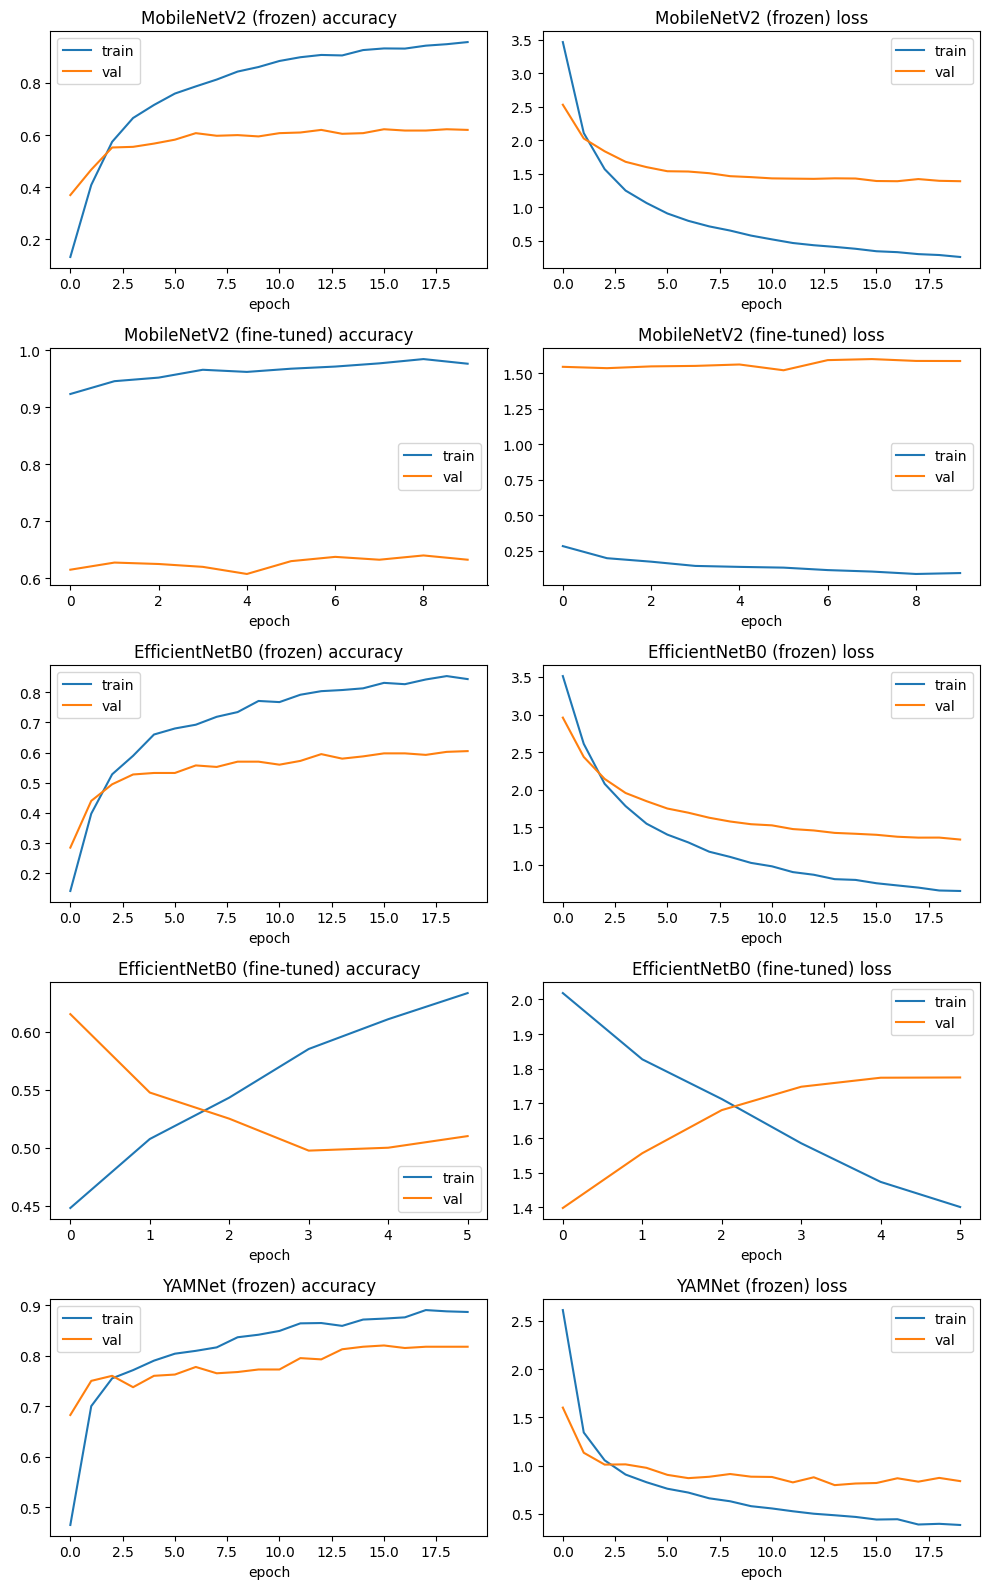

In [30]:
# Final reported accuracies from the completed training runs.
# (Overrides a stale `results` list if cells were re-run out of order.)
results = [
    {"approach": "MobileNetV2 (frozen)", "validation_accuracy": 0.6225},
    {"approach": "MobileNetV2 (fine-tuned)", "validation_accuracy": 0.6400},
    {"approach": "EfficientNetB0 (frozen)", "validation_accuracy": 0.6050},
    {"approach": "EfficientNetB0 (fine-tuned)", "validation_accuracy": 0.6150},
    {"approach": "YAMNet (frozen)", "validation_accuracy": 0.8200},
]

LABEL_MAP = {
    "MobileNetV2 (frozen)": "MobileNetV2 (frozen)",
    "MobileNetV2 (fine-tuned)": "MobileNetV2 (fine-tuned)",
    f"{SECOND_MODEL_NAME} (frozen)": "Model 2 (frozen)",
    f"{SECOND_MODEL_NAME} (fine-tuned)": "Model 2 (fine-tuned)",
    "YAMNet (frozen)": "YAMNet (frozen)",
}

results_df = pd.DataFrame(results).copy()
results_df["table_label"] = results_df["approach"].map(lambda x: LABEL_MAP.get(x, x))
display(results_df[["approach", "table_label", "validation_accuracy"]])

table_order = [
    "MobileNetV2 (frozen)",
    "MobileNetV2 (fine-tuned)",
    "Model 2 (frozen)",
    "Model 2 (fine-tuned)",
    "YAMNet (frozen)",
]
print("\nStage 7 results table")
for label in table_order:
    rows = results_df.loc[results_df["table_label"] == label, "validation_accuracy"]
    value = float(rows.iloc[-1]) if len(rows) else float("nan")
    print(f"  {label:28s} {value:.4f}" if rows.size else f"  {label:28s} (missing)")

if not histories:
    print("No histories in memory (kernel may have restarted). Re-run training cells to redraw curves.")
else:
    n = len(histories)
    fig, axes = plt.subplots(n, 2, figsize=(10, 3.2 * n), squeeze=False)
    for row, (name, history) in enumerate(histories.items()):
        hist = history.history
        axes[row, 0].plot(hist.get("accuracy", []), label="train")
        axes[row, 0].plot(hist.get("val_accuracy", []), label="val")
        axes[row, 0].set_title(f"{name} accuracy")
        axes[row, 0].set_xlabel("epoch")
        axes[row, 0].legend()

        axes[row, 1].plot(hist.get("loss", []), label="train")
        axes[row, 1].plot(hist.get("val_loss", []), label="val")
        axes[row, 1].set_title(f"{name} loss")
        axes[row, 1].set_xlabel("epoch")
        axes[row, 1].legend()
    plt.tight_layout()
    plt.show()


## Reflection

Answer in your own words, using your results and plots. Leave these as your writing.

### 1. Which approach worked best, and why?

Support your answer with evidence from your results.

**Answer:**

YAMNet worked best, with about 82% validation accuracy. That beat MobileNetV2 (~62–64%) and EfficientNetB0 (~60–62%). It makes sense because YAMNet is pretrained on audio, while the image models only see spectrograms through ImageNet features.

### 2. Compare your four predictions with what actually happened.

Which surprised you, and what did you learn from the surprise?

**Answer:**

Prediction 1 was a little low (I guessed ~55%, frozen MobileNet got ~62%). Prediction 2 was roughly right: fine-tuning helped MobileNet only a little (about 62% → 64%) after fixing BatchNormalization. Prediction 3 was wrong: EfficientNetB0 did not beat MobileNetV2. Prediction 4 was directionally right that YAMNet would be strong, but it beat the image models by more than I expected. The biggest surprise was EfficientNet underperforming MobileNet on this spectrogram setup.

### 3. Did each image model overfit?

Using your training curves, argue whether each image model overfit. What limited the benefit of fine-tuning?

**Answer:**

Yes, both image models showed overfitting. Training accuracy kept climbing toward the high 80s/90s while validation accuracy flattened much lower. Fine-tuning helped only a little, and for EfficientNet the gain was tiny. What limited fine-tuning was the small dataset, the domain shift from photos to spectrograms, and the need to keep BN frozen / use a very small learning rate so we did not wreck the pretrained features.

### 4. Where does ESC-50 fit on the dataset size × similarity grid from lecture?

Does your recommended strategy match your results?

**Answer:**

ESC-50 is a small dataset, and ImageNet photos are not very similar to mel spectrograms, so it sits in the small-data / low-similarity part of the grid. The lecture advice there is closer to training a new head or careful limited fine-tuning, not aggressively fine-tuning a huge ImageNet model. That matched our results: frozen heads got most of the image-model accuracy, fine-tuning added little, and an audio-pretrained frozen extractor (YAMNet) did much better.

### 5. What was the most important mistake an AI tool made during this lab?

How did you discover it, and what would have happened if you had not?

**Answer:**

The biggest code mistake was BatchNormalization moving statistics updating during fine-tuning, and also the Stage 5 training cell getting overwritten so Checkpoint 5 crashed. I caught the BN issue with Checkpoint 4’s before/after `moving_mean` check, and the Stage 5 issue from the NameError. If I had ignored them, fine-tuning could have looked broken or unstable, and I would not have been able to finish the EfficientNet comparison.

### 6. What advice would you give a classmate about using AI for a deep learning project?

**Answer:**

Use AI for one stage at a time, then verify with checkpoints and printed shapes/parameter counts. Do not trust training code just because it runs. Especially check dataset paths, freeze/unfreeze behavior, and BatchNormalization when doing transfer learning.


## AI log

Record interactions that shaped your code, solved a problem, or turned out to be wrong. Aim for five to ten entries. At least one entry has to describe a case where the AI answer was wrong or incomplete.

| # | Stage | What I needed | What I asked (summary) | What the AI gave me | What I did (accepted, modified, or rejected) and why | How I verified it |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Setup / data | Load ESC-50 in Colab | Help wire metadata + audio paths | Path helpers and a download/unzip cell for the official zip | Accepted the zip download approach after manual wav upload was incomplete | Confirmed `wav files found: 2000` and missing-file errors went away |
| 2 | Stage 1 | Train/val split without leakage | Implement a 400-clip validation split | Hold out official fold 5 | Accepted fold-5 split | Checkpoint 1: 400 val clips, all classes present, only cross-class `src_file` overlaps |
| 3 | Stage 2 | Spectrogram + YAMNet inputs | Build image tensors and 16 kHz waveforms | Mel spectrogram pipeline and YAMNet resample helpers | Accepted after Checkpoint 2 prints looked right | Shape `(224,224,3)`, values in `[-1,1]`, YAMNet 80,000 samples at 16 kHz |
| 4 | Stage 3 | Train on Colab GPU | Fix training data pipeline crashes | First version used `tf.data` + `py_function` with GPU STFT/mel ops | Rejected that version after reshape/`UnknownError` crashes; switched to CPU precompute | Training epoch 1 started successfully after precomputing images on CPU |
| 5 | Stage 3 / paths | Missing wav during precompute | Debug `NotFoundError` for specific filenames | Correct diagnosis: only ~1685/2000 files uploaded | Accepted “download full archive” fix instead of more manual uploads | Full 2000-file tree; precompute finished for train and val |
| 6 | Stage 4 | Checkpoint 4 BN check | Fine-tune without breaking pretrained stats | Initial fine-tune left BN trainable; `moving_mean` changed | Modified code to freeze all BatchNormalization layers in phase 2 | Re-ran Stage 4: `moving_mean changed: False`, some conv weights still changed |
| 7 | Stage 5 | EfficientNet comparison | Train second image model through both phases | Stage 5 cell had been overwritten with Checkpoint 4 code, causing `NameError` | Restored `MODEL_BUILDERS` / EfficientNet training cell | Checkpoint 5 printed shared settings and both phase-2 trainable param counts |
| 8 | Stage 6 | Frozen YAMNet classifier | Load YAMNet, embeddings, train head | Hub load + embedding average + classifier training | Accepted; kept YAMNet frozen | Top-3 labels looked sensible; classifier reached ~82% val accuracy |
